In [28]:
# Листинг 1 — Создание окружения и установка зависимостей
# !python -m venv .venv
# !.venv\Scripts\activate
# !python -m pip install --upgrade pip
# !python -m pip install "numpy>=1.26" "pandas>=2.1" "matplotlib>=3.8" "seaborn>=0.13" "scikit-learn>=1.4,<2" jupyterlab

In [29]:
# Листинг 2 — Базовые импорты и единый seed

# Стандартная библиотека используется для времени и путей к файлам.
from pathlib import Path
from time import perf_counter

# Научный стек: таблицы, массивы, графики и клонирование моделей.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone

# Фиксируем один seed для всех случайных разбиений эксперимента.
SEED = 42
np.random.seed(SEED)

# Печатаем версии: они должны быть указаны в отчёте.
import sklearn
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.5.3
pandas: 3.0.6
scikit-learn: 1.9.1


In [30]:
# Листинг 3 — Функция загрузки варианта из локального архива
# Каталог должен находиться рядом с текущим Jupyter Notebook.
DATA_DIR = Path("ML_Lab3_Datasets")

def load_local_variant(variant, data_dir=DATA_DIR):
    """Возвращает признаки, целевую переменную и строку manifest."""
    # dtype=str сохраняет идентификаторы и имена столбцов без преобразований.
    manifest = pd.read_csv(data_dir / "manifest.csv", dtype=str)
    row = manifest.loc[manifest["variant"] == str(variant)]
    if row.empty:
        raise ValueError(f"Вариант {variant} отсутствует в manifest.csv")
    card = row.iloc[0]

    # Стандартные обозначения пропусков преобразуем в np.nan.
    frame = pd.read_csv(
        data_dir / card["file_name"],
        na_values=["?", "NA", "null", ""],
    )
    target_column = card["target_column"]
    if target_column not in frame.columns:
        raise KeyError(f"Нет целевого столбца {target_column!r}")

    # Объекты без целевой метки нельзя использовать в обучении с учителем.
    labeled = frame[target_column].notna()
    removed = int((~labeled).sum())
    if removed:
        print(f"Исключено объектов без метки: {removed}")
    X = frame.loc[labeled].drop(columns=target_column).reset_index(drop=True)
    y = frame.loc[labeled, target_column].astype(str).reset_index(drop=True)
    return X, y, card

In [31]:
# Листинг 5 — Импорты моделей и метрик (без загрузки example_moons.csv)
# Импортируем компоненты scikit-learn, используемые далее в примере.
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR

In [32]:
# Листинг 7 — kNN-классификатор средствами NumPy
def manual_knn_predict(
    X_train,
    y_train,
    X_query,
    *,
    k=5,
    weighted=False,
):
    """Предсказывает класс каждого объекта из X_query."""
    # Явно преобразуем входы в массивы и проверяем допустимость k.
    X_train = np.asarray(X_train, dtype=float)
    X_query = np.asarray(X_query, dtype=float)
    y_train = np.asarray(y_train)
    if not 1 <= k <= len(X_train):
        raise ValueError("k должно лежать между 1 и размером train")

    predictions = []
    for query in X_query:
        # Евклидово расстояние вычисляется до каждого объекта train.
        distances = np.sqrt(np.sum((X_train - query) ** 2, axis=1))
        order = np.argsort(distances, kind="mergesort")[:k]
        neighbor_labels = y_train[order]
        neighbor_distances = distances[order]

        # При точном совпадении голосуют только соседи с нулевой дистанцией.
        if weighted and np.any(neighbor_distances <= 1e-12):
            weights = (neighbor_distances <= 1e-12).astype(float)
        # В остальных случаях взвешенный режим усиливает близких соседей.
        elif weighted:
            weights = 1.0 / neighbor_distances
        else:
            weights = np.ones(k, dtype=float)

        # Суммируем голоса отдельно для каждого встреченного класса.
        scores = {}
        for label, weight in zip(neighbor_labels, weights):
            scores[label] = scores.get(label, 0.0) + float(weight)

        # При равенстве голосов выбираем минимальную метку, как sklearn.
        predictions.append(max(sorted(scores), key=scores.get))
    return np.asarray(predictions)

In [33]:
# Листинг 10 — Таблица метрик классификации
def classification_metrics(y_true, y_pred):
    """Возвращает три взаимодополняющие метрики классификации."""
    # Accuracy удобна для общего понимания доли правильных ответов.
    accuracy = accuracy_score(y_true, y_pred)

    # Balanced accuracy одинаково учитывает полноту каждого класса.
    balanced = balanced_accuracy_score(y_true, y_pred)

    # Macro-F1 одинаково взвешивает классы и служит основным критерием.
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    return {
        "accuracy": accuracy,
        "balanced_accuracy": balanced,
        "macro_f1": macro_f1,
    }

In [34]:
# Листинг 13 — Измерение fit, predict и размера опорного множества
def measure_classifier(name, estimator, X_train, y_train, X_val, y_val):
    """Переобучает модель и измеряет качество и время."""
    # clone создаёт чистую модель с теми же выбранными параметрами.
    model = clone(estimator)
    start = perf_counter()
    model.fit(X_train, y_train)
    fit_ms = 1000.0 * (perf_counter() - start)

    # Время приводим к 1000 объектам для удобства сравнения.
    start = perf_counter()
    prediction = model.predict(X_val)
    predict_seconds = perf_counter() - start
    predict_ms_1000 = 1_000_000.0 * predict_seconds / len(X_val)

    # Для SVC считаем опорные векторы, для kNN — сохранённый train.
    inner_model = model.named_steps["model"]
    if hasattr(inner_model, "n_support_"):
        stored_objects = int(inner_model.n_support_.sum())
    else:
        stored_objects = len(X_train)

    metrics = classification_metrics(y_val, prediction)
    return {
        "model": name,
        **metrics,
        "fit_ms": fit_ms,
        "predict_ms_per_1000": predict_ms_1000,
        "stored_objects": stored_objects,
        "stored_share": stored_objects / len(X_train),
    }

In [35]:
# Дополнение к листингу 13 (этап 6 методички): времена — медиана не менее чем из трёх повторов
# Функция сохраняет имя, аргументы и формат результата листинга 13.
from statistics import median

_measure_once = measure_classifier

def measure_classifier(name, estimator, X_train, y_train, X_val, y_val, repeats=5):
    runs = [
        _measure_once(name, estimator, X_train, y_train, X_val, y_val)
        for _ in range(repeats)
    ]
    result = dict(runs[0])
    result["fit_ms"] = median(run["fit_ms"] for run in runs)
    result["predict_ms_per_1000"] = median(run["predict_ms_per_1000"] for run in runs)
    return result

In [36]:
# Листинг 14 — Решающие области kNN, linear SVM и RBF SVM
def plot_decision_region(ax, estimator, X, y, title):
    """Обучает модель и отображает её решение на двумерной сетке."""
    # Сетку строим в исходном пространстве; scaling выполняет Pipeline.
    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x1_min, x1_max, 300),
        np.linspace(x2_min, x2_max, 300),
    )

    # Для честной демонстрации модель обучается только на train.
    model = clone(estimator)
    model.fit(X, y)
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)

    # Фон показывает классы модели, точки — реальные train-объекты.
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=18)
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

In [37]:
# Дополнение к листингу 14: у варианта 10 классов, поэтому цвета и уровни фона заданы по числу классов
def plot_decision_region(ax, estimator, X, y, title):
    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x1_min, x1_max, 300),
        np.linspace(x2_min, x2_max, 300),
    )
    model = clone(estimator)
    model.fit(X, y)
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    levels = np.arange(-0.5, len(np.unique(y)) + 0.5)
    ax.contourf(xx, yy, zz, levels=levels, alpha=0.25, cmap="tab10", vmin=-0.5, vmax=9.5)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="tab10", vmin=-0.5, vmax=9.5, s=10)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

In [38]:
# Листинг 18 — Универсальный протокол для смешанных признаков
# Импортируем преобразователи для числовых и категориальных столбцов.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

VARIANT = 4  # Замените единицу номером своего варианта.
X_variant, y_variant, card = load_local_variant(VARIANT)
print(card[[
    "dataset_name",
    "data_id",
    "file_name",
    "target_column",
]])

y_variant = y_variant.astype(int)
print(y_variant.value_counts(dropna=False))

# Сначала откладываем test, затем выделяем validation из train_full.
X_train_full_v, X_test_v, y_train_full_v, y_test_v = train_test_split(
    X_variant,
    y_variant,
    test_size=0.20,
    stratify=y_variant,
    random_state=SEED,
)
X_train_v, X_val_v, y_train_v, y_val_v = train_test_split(
    X_train_full_v,
    y_train_full_v,
    test_size=0.25,
    stratify=y_train_full_v,
    random_state=SEED,
)

# Сбрасываем индексы, чтобы таблицы ошибок не выравнивались по старым индексам.
X_train_v = X_train_v.reset_index(drop=True)
X_val_v = X_val_v.reset_index(drop=True)
X_test_v = X_test_v.reset_index(drop=True)
y_train_v = y_train_v.reset_index(drop=True)
y_val_v = y_val_v.reset_index(drop=True)
y_test_v = y_test_v.reset_index(drop=True)

def make_preprocessor(X_train):
    """Создаёт преобразователь, но не обучает его заранее."""
    # Типы столбцов определяем только по структуре train.
    numeric = X_train.select_dtypes(include="number").columns.tolist()
    categorical = [column for column in X_train.columns
                   if column not in numeric]
    transformers = []

    # Числа: медианная импутация, затем стандартизация расстояний.
    if numeric:
        numeric_pipeline = Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ])
        transformers.append(("numeric", numeric_pipeline, numeric))

    # Категории: частая категория и плотное one-hot кодирование.
    if categorical:
        categorical_pipeline = Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            )),
        ])
        transformers.append(("categorical", categorical_pipeline, categorical))

    # sparse_threshold=0 гарантирует плотный массив для всех рассматриваемых моделей.
    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=0.0,
    )

preprocessor = make_preprocessor(X_train_v)
print("Train / validation / test:",
      len(X_train_v), len(X_val_v), len(X_test_v))

# Константный baseline обучается на train именно текущего варианта.
baseline_v = DummyClassifier(strategy="most_frequent")
baseline_v.fit(X_train_v, y_train_v)
baseline_prediction_v = baseline_v.predict(X_val_v)
print("Baseline validation:",
      classification_metrics(y_val_v, baseline_prediction_v))

dataset_name     mfeat-karhunen
data_id                      16
file_name        variant_04.csv
target_column             class
Name: 4, dtype: str
class
1     200
2     200
3     200
4     200
5     200
6     200
7     200
8     200
9     200
10    200
Name: count, dtype: int64
Train / validation / test: 1200 400 400
Baseline validation: {'accuracy': 0.1, 'balanced_accuracy': 0.1, 'macro_f1': 0.01818181818181818}


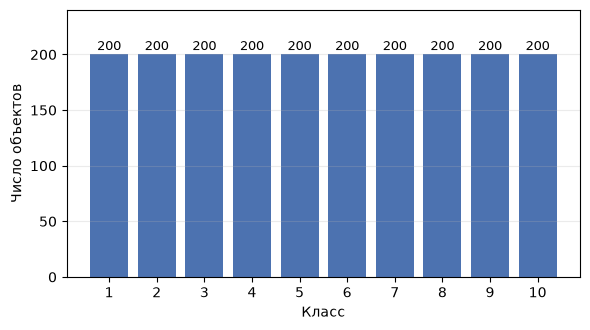

In [39]:
# Рисунок 1 — распределение объектов по классам.
IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(exist_ok=True)

class_counts = y_variant.astype(int).value_counts().sort_index()

plt.figure(figsize=(6, 3.4))
plt.bar(class_counts.index.astype(str), class_counts.values, color="#4c72b0")
for position, count in enumerate(class_counts.values):
    plt.text(position, count + 4, str(count), ha="center", fontsize=9)
plt.xlabel("Класс")
plt.ylabel("Число объектов")
plt.ylim(0, class_counts.max() * 1.2)
plt.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "class_dist.png", dpi=200)
plt.show()

In [40]:
# Таблица 3 — Карточка исходного набора
print("Вариант и data_id:", VARIANT, "/", card["data_id"], card["dataset_name"])
print("Размер:", X_variant.shape[0], "объектов,", X_variant.shape[1], "исходных признаков")
print("Целевая переменная:", card["target_column"], "| классов:", y_variant.nunique())
print("Баланс классов:", class_counts.to_dict())
print("Типы признаков:", X_variant.dtypes.value_counts().to_dict())
print("Пропуски:", int(X_variant.isna().sum().sum()))
print("Полных дубликатов:", int(pd.concat([X_variant, y_variant.rename("class")], axis=1).duplicated().sum()), "(оставлены)")
print("Столбцов-идентификаторов:", sum(X_variant[c].nunique() == len(X_variant) for c in X_variant.columns))

Вариант и data_id: 4 / 16 mfeat-karhunen
Размер: 2000 объектов, 64 исходных признаков
Целевая переменная: class | классов: 10
Баланс классов: {1: 200, 2: 200, 3: 200, 4: 200, 5: 200, 6: 200, 7: 200, 8: 200, 9: 200, 10: 200}
Типы признаков: {dtype('float64'): 64}
Пропуски: 0
Полных дубликатов: 6 (оставлены)
Столбцов-идентификаторов: 0


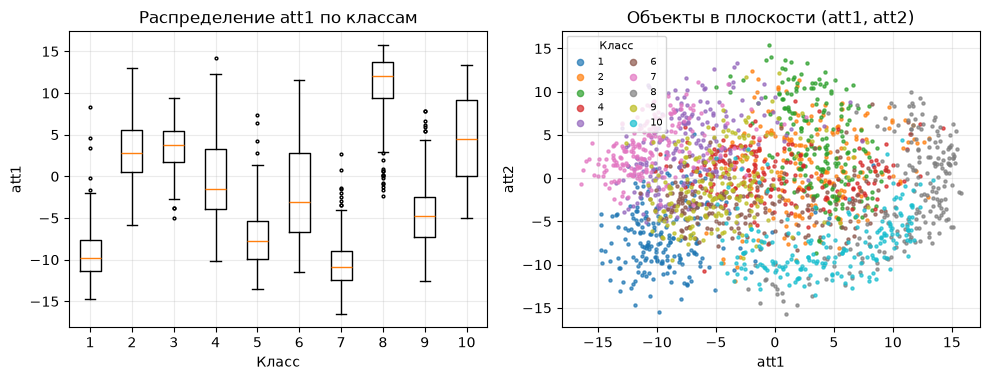

In [41]:
class_labels = sorted(y_variant.astype(int).unique())
colors = plt.get_cmap("tab10")
y_numeric = y_variant.astype(int)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
axes[0].boxplot(
    [X_variant.loc[y_numeric == label, "att1"] for label in class_labels],
    flierprops=dict(markersize=2),
)
axes[0].set_xticklabels([str(label) for label in class_labels])
axes[0].set_xlabel("Класс")
axes[0].set_ylabel("att1")
axes[0].set_title("Распределение att1 по классам")
axes[0].grid(alpha=0.25)
for index, label in enumerate(class_labels):
    mask = y_numeric == label
    axes[1].scatter(
        X_variant.loc[mask, "att1"], X_variant.loc[mask, "att2"],
        s=5, color=colors(index), alpha=0.7, label=str(label),
    )
axes[1].set_xlabel("att1")
axes[1].set_ylabel("att2")
axes[1].set_title("Объекты в плоскости (att1, att2)")
axes[1].grid(alpha=0.25)
axes[1].legend(title="Класс", ncol=2, fontsize=7, title_fontsize=8, markerscale=2)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "features.png", dpi=200)
plt.show()

In [42]:
# Листинг 19 — Ручной и библиотечный kNN на первых объектах validation
# Отдельная копия preprocessing обучается исключительно для проверки kNN.
manual_preprocessor = clone(preprocessor)
X_train_manual = manual_preprocessor.fit_transform(X_train_v)
X_val_manual = manual_preprocessor.transform(X_val_v)

# Ограничиваем только число проверяемых запросов, но сохраняем весь train.
check_size = min(50, len(X_val_manual))
k_manual = min(5, len(X_train_manual))
manual_prediction_v = manual_knn_predict(
    X_train_manual,
    y_train_v.to_numpy(),
    X_val_manual[:check_size],
    k=k_manual,
    weighted=True,
)

# Библиотечная модель получает тот же преобразованный массив.
library_knn_v = KNeighborsClassifier(
    n_neighbors=k_manual,
    weights="distance",
    p=2,
)
library_knn_v.fit(X_train_manual, y_train_v)
library_prediction_v = library_knn_v.predict(
    X_val_manual[:check_size]
)

# В отчёте приведите долю совпадений и разберите любое расхождение.
agreement_v = np.mean(manual_prediction_v == library_prediction_v)
print("Совпадение ручного и библиотечного kNN:", agreement_v)

Совпадение ручного и библиотечного kNN: 1.0


In [43]:
# Листинг 9 — Эксперимент с искусственно искажённым масштабом (адаптация к варианту 4)
# Умножаем второй признак на 100, не изменяя информацию в данных.
X_train_distorted = X_train_v.copy()
X_val_distorted = X_val_v.copy()
X_train_distorted.iloc[:, 1] *= 100.0
X_val_distorted.iloc[:, 1] *= 100.0

# Копия preprocessing без стандартизации: импутация сохраняется.
preprocessor_without_scaling = clone(preprocessor).set_params(
    numeric__scale="passthrough",
)

# Модель без стандартизации почти игнорирует остальные признаки.
knn_without_scaling = Pipeline([
    ("preprocess", preprocessor_without_scaling),
    ("model", KNeighborsClassifier(
        n_neighbors=11,
        weights="distance",
    )),
])
knn_without_scaling.fit(X_train_distorted, y_train_v)
pred_without = knn_without_scaling.predict(X_val_distorted)

# Pipeline обучает StandardScaler только на train, затем применяет kNN.
knn_with_scaling = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", KNeighborsClassifier(
        n_neighbors=11,
        weights="distance",
    )),
])
knn_with_scaling.fit(X_train_distorted, y_train_v)
pred_with = knn_with_scaling.predict(X_val_distorted)

# Сравниваем модели одной метрикой и на одном validation.
print("Без scaling:", f1_score(y_val_v, pred_without, average="macro"))
print("Со scaling:", f1_score(y_val_v, pred_with, average="macro"))

Без scaling: 0.5515089272884296
Со scaling: 0.9403213924808513


In [44]:
# Таблица 4 — Ближайшие соседи и macro-F1 до и после искажения масштаба
# Те же kNN, обученные на исходном (неискажённом) train.
knn_plain_without = clone(knn_without_scaling).fit(X_train_v, y_train_v)
knn_plain_with = clone(knn_with_scaling).fit(X_train_v, y_train_v)

def neighbors(model, X):
    """Индексы соседей первых check_size объектов validation."""
    Z = model[:-1].transform(X.iloc[:check_size])
    return model.named_steps["model"].kneighbors(Z, return_distance=False)

def common_share(a, b):
    """Средняя доля общих соседей двух наборов."""
    return np.mean([len(set(r) & set(s)) / len(r) for r, s in zip(a, b)])

# Эталон — исходные данные со стандартизацией.
reference = neighbors(knn_plain_with, X_val_v)
scaling_table = pd.DataFrame([
    {"данные": "исходные", "scaling": "да",
     "macro_f1": f1_score(y_val_v, knn_plain_with.predict(X_val_v), average="macro"),
     "общих соседей": 1.0},
    {"данные": "исходные", "scaling": "нет",
     "macro_f1": f1_score(y_val_v, knn_plain_without.predict(X_val_v), average="macro"),
     "общих соседей": common_share(reference, neighbors(knn_plain_without, X_val_v))},
    {"данные": "att2 x100", "scaling": "да",
     "macro_f1": f1_score(y_val_v, pred_with, average="macro"),
     "общих соседей": common_share(reference, neighbors(knn_with_scaling, X_val_distorted))},
    {"данные": "att2 x100", "scaling": "нет",
     "macro_f1": f1_score(y_val_v, pred_without, average="macro"),
     "общих соседей": common_share(reference, neighbors(knn_without_scaling, X_val_distorted))},
])
print(scaling_table.round(4))

      данные scaling  macro_f1  общих соседей
0   исходные      да    0.9403         1.0000
1   исходные     нет    0.9750         0.7345
2  att2 x100      да    0.9403         1.0000
3  att2 x100     нет    0.5515         0.0818


In [45]:
# Листинг 20 — GridSearchCV для kNN индивидуального варианта
# Фиксированные фолды обеспечивают сопоставимость всех конфигураций.
variant_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)
knn_variant_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", KNeighborsClassifier()),
])

# Нечётные k уменьшают вероятность ничьей в бинарной классификации.
knn_variant_grid = {
    "model__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}
knn_search_v = GridSearchCV(
    knn_variant_pipeline,
    knn_variant_grid,
    scoring="f1_macro",
    cv=variant_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)
knn_search_v.fit(X_train_v, y_train_v)

# Validation используется только после завершения внутреннего поиска.
knn_val_v = knn_search_v.predict(X_val_v)
print("kNN best:", knn_search_v.best_params_)
print(classification_metrics(y_val_v, knn_val_v))

# Таблица cv_results_ нужна для графика качества в зависимости от k.
knn_cv_results = pd.DataFrame(knn_search_v.cv_results_)
columns = [
    "param_model__n_neighbors",
    "param_model__weights",
    "param_model__p",
    "mean_test_score",
    "std_test_score",
]
print(knn_cv_results[columns].sort_values(
    "mean_test_score",
    ascending=False,
).head(10))

kNN best: {'model__n_neighbors': 3, 'model__p': 1, 'model__weights': 'distance'}
{'accuracy': 0.9625, 'balanced_accuracy': 0.9625, 'macro_f1': 0.9627713535556672}
    param_model__n_neighbors param_model__weights  param_model__p  \
5                          3             distance               1   
11                         5             distance               2   
1                          1             distance               1   
0                          1              uniform               1   
9                          5             distance               1   
4                          3              uniform               1   
7                          3             distance               2   
15                         7             distance               2   
21                        15             distance               1   
17                        11             distance               1   

    mean_test_score  std_test_score  
5          0.940732        0.012041  
1

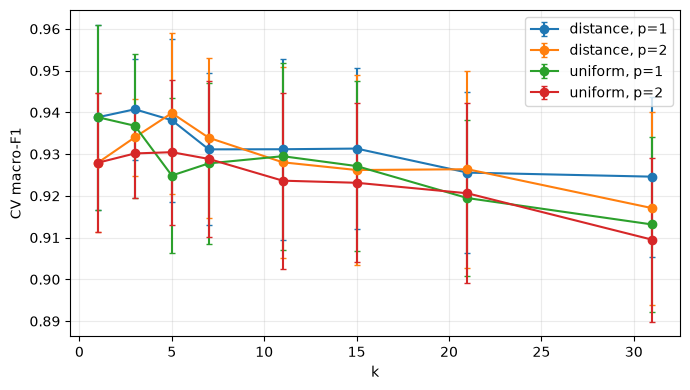

In [46]:
# Рисунок 2 — CV macro-F1 kNN в зависимости от k, weights и p
plt.figure(figsize=(7, 4))
for (weights, p), part in knn_cv_results.groupby(["param_model__weights", "param_model__p"]):
    part = part.sort_values("param_model__n_neighbors")
    plt.errorbar(
        part["param_model__n_neighbors"].astype(int), part["mean_test_score"],
        yerr=part["std_test_score"], marker="o", capsize=2,
        label=f"{weights}, p={p}",
    )
plt.xlabel("k")
plt.ylabel("CV macro-F1")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "knn_cv.png", dpi=200)
plt.show()

In [47]:
# Листинг 21 — Линейный и RBF-SVM индивидуального варианта
# При сильном дисбалансе дополнительно проверяем class_weight="balanced".
class_counts = y_train_v.value_counts()
imbalance_ratio = class_counts.max() / class_counts.min()
weight_options = [None, "balanced"] if imbalance_ratio >= 2 else [None]

# Линейная модель проверяет, достаточно ли гиперплоскости.
linear_variant_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", SVC(kernel="linear")),
])
linear_search_v = GridSearchCV(
    linear_variant_pipeline,
    {
        "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        "model__class_weight": weight_options,
    },
    scoring="f1_macro",
    cv=variant_cv,
    n_jobs=-1,
    refit=True,
)
linear_search_v.fit(X_train_v, y_train_v)

# RBF-модель настраивает локальность ядра и штраф за нарушения.
rbf_variant_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", SVC(kernel="rbf")),
])
rbf_search_v = GridSearchCV(
    rbf_variant_pipeline,
    {
        "model__C": [0.1, 1.0, 10.0, 100.0],
        "model__gamma": ["scale", 0.01, 0.1, 1.0],
        "model__class_weight": weight_options,
    },
    scoring="f1_macro",
    cv=variant_cv,
    n_jobs=-1,
    refit=True,
)
rbf_search_v.fit(X_train_v, y_train_v)

# Сравниваем семейства на одном validation и сохраняем параметры.
for name, search in {
    "linear SVM": linear_search_v,
    "RBF SVM": rbf_search_v,
}.items():
    prediction = search.predict(X_val_v)
    support_count = int(
        search.best_estimator_.named_steps["model"].n_support_.sum()
    )
    print(name, search.best_params_)
    print(classification_metrics(y_val_v, prediction))
    print("Опорных векторов:", support_count)
    print("Доля опорных векторов:", support_count / len(X_train_v))

linear SVM {'model__C': 0.01, 'model__class_weight': None}
{'accuracy': 0.9625, 'balanced_accuracy': 0.9625, 'macro_f1': 0.9624770539227161}
Опорных векторов: 696
Доля опорных векторов: 0.58
RBF SVM {'model__C': 10.0, 'model__class_weight': None, 'model__gamma': 0.01}
{'accuracy': 0.9775, 'balanced_accuracy': 0.9774999999999998, 'macro_f1': 0.9774608698239963}
Опорных векторов: 790
Доля опорных векторов: 0.6583333333333333


In [48]:
# Таблица 5 — CV macro-F1 лучших конфигураций и влияние C (linear) и C × gamma (RBF)
for name, search in {"kNN": knn_search_v, "linear SVM": linear_search_v, "RBF SVM": rbf_search_v}.items():
    print(name, "CV macro-F1: %.4f ± %.4f" % (
        search.cv_results_["mean_test_score"][search.best_index_],
        search.cv_results_["std_test_score"][search.best_index_]))

linear_cv_results = pd.DataFrame(linear_search_v.cv_results_)
print(linear_cv_results[["param_model__C", "mean_test_score", "std_test_score"]])

rbf_cv_results = pd.DataFrame(rbf_search_v.cv_results_)
print(rbf_cv_results.pivot_table(
    index="param_model__C", columns="param_model__gamma",
    values="mean_test_score", aggfunc="max",
).round(4))

kNN CV macro-F1: 0.9407 ± 0.0120
linear SVM CV macro-F1: 0.9549 ± 0.0097
RBF SVM CV macro-F1: 0.9700 ± 0.0119
   param_model__C  mean_test_score  std_test_score
0            0.01         0.954910        0.009694
1            0.10         0.936516        0.012496
2            1.00         0.929819        0.009635
3           10.00         0.929819        0.009635
4          100.00         0.929819        0.009635
param_model__gamma    0.01     0.1     1.0   scale
param_model__C                                    
0.1                 0.9199  0.3315  0.0518  0.9234
1.0                 0.9658  0.8032  0.0887  0.9683
10.0                0.9700  0.8153  0.1028  0.9674
100.0               0.9700  0.8153  0.1028  0.9674


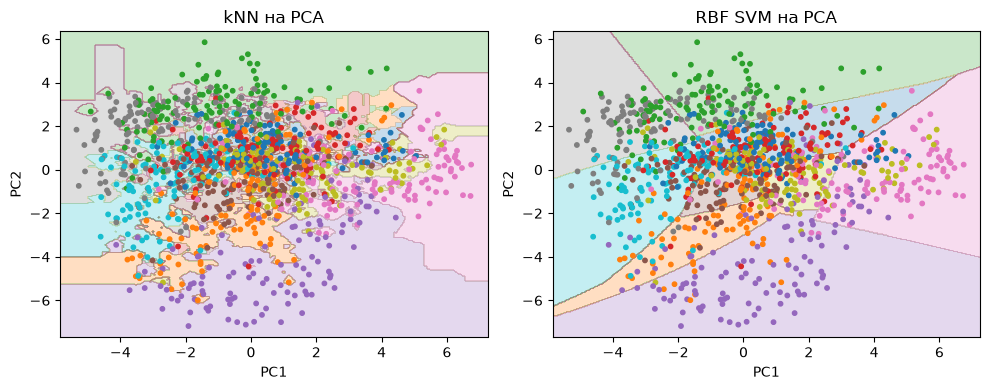

Explained variance: 0.17173766765560822


In [49]:
# Листинг 22 — PCA-проекция и визуализационные модели
# PCA и LabelEncoder применяются только в блоке визуализации.
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder

# Preprocessing и PCA обучаются только на train.
visual_preprocessor = clone(preprocessor)
X_train_encoded = visual_preprocessor.fit_transform(X_train_v)
pca = PCA(n_components=2, random_state=SEED)
X_train_2d = pca.fit_transform(X_train_encoded)

# Числовые коды нужны только для цветовой карты двумерного графика.
label_encoder = LabelEncoder()
y_train_codes = label_encoder.fit_transform(y_train_v)

# Выбираем лучшее SVM-семейство по validation, не обращаясь к test.
svm_searches = {
    "linear SVM": linear_search_v,
    "RBF SVM": rbf_search_v,
}
svm_visual_name = max(
    svm_searches,
    key=lambda name: f1_score(
        y_val_v,
        svm_searches[name].predict(X_val_v),
        average="macro",
    ),
)
svm_inner = clone(
    svm_searches[svm_visual_name].best_estimator_.named_steps["model"]
)
knn_inner = clone(
    knn_search_v.best_estimator_.named_steps["model"]
)

# После PCA масштабируем компоненты внутри каждой иллюстративной модели.
visual_models = {
    "kNN на PCA": Pipeline([
        ("scale", StandardScaler()),
        ("model", knn_inner),
    ]),
    f"{svm_visual_name} на PCA": Pipeline([
        ("scale", StandardScaler()),
        ("model", svm_inner),
    ]),
}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, visual_models.items()):
    plot_decision_region(ax, model, X_train_2d, y_train_codes, name)
plt.tight_layout()
plt.show()

# Доля объяснённой дисперсии показывает потери при двумерной проекции.
print("Explained variance:", pca.explained_variance_ratio_.sum())

        model  accuracy  balanced_accuracy  macro_f1   fit_ms  \
2     RBF SVM    0.9775             0.9775    0.9775  40.5028   
0         kNN    0.9625             0.9625    0.9628  11.3451   
1  linear SVM    0.9625             0.9625    0.9625  27.6731   

   predict_ms_per_1000  stored_objects  stored_share  
2              59.5727             790        0.6583  
0              32.3252            1200        1.0000  
1              22.8500             696        0.5800  
Финальная модель: RBF SVM
{'accuracy': 0.9775, 'balanced_accuracy': 0.9774999999999998, 'macro_f1': 0.9773602477721548}
              precision    recall  f1-score   support

           1      1.000     0.975     0.987        40
           2      0.975     0.975     0.975        40
           3      1.000     1.000     1.000        40
           4      0.952     1.000     0.976        40
           5      0.976     1.000     0.988        40
           6      0.973     0.900     0.935        40
           7      1.

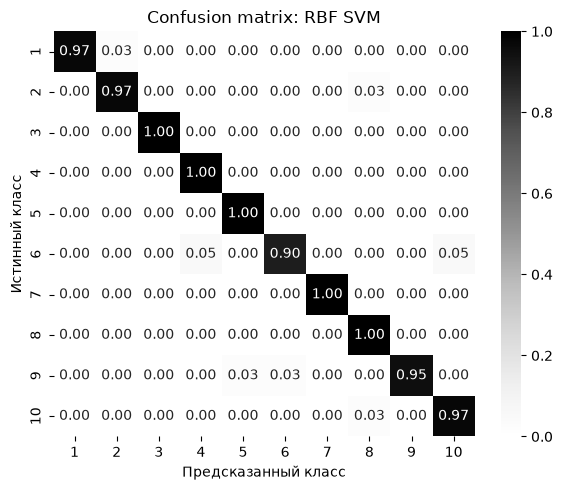

In [ ]:
# Листинг 23 — Выбор семейства и итоговая оценка варианта
# Формируем список уже настроенных моделей; test пока не используется.
variant_candidates = {
    "kNN": knn_search_v.best_estimator_,
    "linear SVM": linear_search_v.best_estimator_,
    "RBF SVM": rbf_search_v.best_estimator_,
}
validation_table = pd.DataFrame([
    measure_classifier(
        name, model, X_train_v, y_train_v, X_val_v, y_val_v
    )
    for name, model in variant_candidates.items()
]).sort_values("macro_f1", ascending=False)
print(validation_table.round(4))

# Победитель фиксируется по validation macro-F1 до открытия test.
best_variant_name = validation_table.iloc[0]["model"]
best_variant_pipeline = variant_candidates[best_variant_name]
X_train_val_v = pd.concat([X_train_v, X_val_v], ignore_index=True)
y_train_val_v = pd.concat([y_train_v, y_val_v], ignore_index=True)
final_variant_model = clone(best_variant_pipeline)
final_variant_model.fit(X_train_val_v, y_train_val_v)

# Единственное обращение к test даёт итоговые метрики работы.
test_prediction_v = final_variant_model.predict(X_test_v)
print("Финальная модель:", best_variant_name)
print(classification_metrics(y_test_v, test_prediction_v))
print(classification_report(y_test_v, test_prediction_v, digits=3))

# Сохраняем ошибочные объекты для содержательного анализа.
error_table_v = X_test_v.copy()
error_table_v["true"] = y_test_v.to_numpy()
error_table_v["predicted"] = test_prediction_v
error_table_v = error_table_v.loc[
    error_table_v["true"] != error_table_v["predicted"]
]
print("Ошибок на test:", len(error_table_v))
print(error_table_v.head(10))

# Матрица ошибок строится по уже полученному финальному прогнозу.
labels_v = final_variant_model.classes_
matrix_v = confusion_matrix(y_test_v, test_prediction_v, labels=labels_v, normalize="true")
plt.figure(figsize=(6, 5))
sns.heatmap(
    matrix_v, annot=True, fmt=".2f", cmap="Greys",
    xticklabels=labels_v, yticklabels=labels_v,
)
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title(f"Confusion matrix: {best_variant_name}")
plt.tight_layout()
plt.show()